# Practical 1: Rice Farm Remote Sensing, Geemap and Spatial Storage
### Hands-on Session: Sentinel-2 Extraction, Indices, Geemap Exploration, GeoParquet and Pixel-level Zarr Cube

## Step 1: Import core geospatial and remote sensing libraries

In [2]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import mapping
import xarray as xr
import matplotlib.pyplot as plt
import ee
import geemap
from dotenv import load_dotenv

## Step 2: Set working directory and load environment variables

In [3]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

load_dotenv()
print("Working directory:", os.getcwd())

Working directory: c:\Users\Admin\Desktop\DevFestAbuja


## Step 3: Initialize Google Earth Engine using Service Account credentials

In [4]:
PROJECT_ID = os.getenv('GEE_PROJECT_ID', 'ee-adedoyinsamuel25')
KEY_PATH = os.getenv('GEE_SERVICE_ACCOUNT_KEY', 'credentials/ee-adedoyinsamuel25-5674f2f97650.json')

with open(KEY_PATH, 'r') as f:
    key_data = json.load(f)
service_email = key_data.get('client_email')

credentials = ee.ServiceAccountCredentials(service_email, KEY_PATH)
ee.Initialize(credentials, project=PROJECT_ID)
print("Earth Engine initialized with service account:", service_email)

Earth Engine initialized with service account: gee-account-samuel@ee-adedoyinsamuel25.iam.gserviceaccount.com


## Step 4: Load farm boundary shapefile with GeoPandas

In [5]:
gdf_farm = gpd.read_file('farm_boundary/farm_boundary.shp')
if gdf_farm.crs is None or gdf_farm.crs.to_epsg() != 4326:
    gdf_farm = gdf_farm.to_crs(epsg=4326)

if 'plot_id' not in gdf_farm.columns:
    gdf_farm['plot_id'] = [f'Plot_{i+1:02d}' for i in range(len(gdf_farm))]

print("Total farm plots:", len(gdf_farm))
display(gdf_farm[['plot_id', 'geometry']].head())

Total farm plots: 17


,plot_id,geometry
0,Plot_01,"POLYGON ((8.32081 7.88857, 8.32308 7.89014, 8...."
1,Plot_02,"POLYGON ((8.32315 7.89014, 8.32552 7.89175, 8...."
2,Plot_03,"POLYGON ((8.32555 7.89166, 8.32756 7.89316, 8...."
3,Plot_04,"POLYGON ((8.32761 7.89316, 8.32996 7.89476, 8...."
4,Plot_05,"POLYGON ((8.3301 7.89467, 8.33173 7.8959, 8.33..."


## Step 5: Convert GeoPandas geometries to Earth Engine FeatureCollection

In [6]:
ee_features = [ee.Feature(ee.Geometry(mapping(r.geometry)), {'plot_id': r['plot_id']}) for _, r in gdf_farm.iterrows()]
fc_farm = ee.FeatureCollection(ee_features)
print("Earth Engine FeatureCollection created with feature count:", fc_farm.size().getInfo())

Earth Engine FeatureCollection created with feature count: 17


## Step 6: Explore farm plots interactively with Geemap

In [7]:
centroid = gdf_farm.unary_union.centroid
Map = geemap.Map(center=[centroid.y, centroid.x], zoom=15)
Map.add_basemap("HYBRID")

styled_plots = fc_farm.style(color='00FF00', fillColor='00FF0022', width=2)
Map.addLayer(styled_plots, {}, "Rice Farm Plots (17 Plots)")
Map.add_layer_control()
Map

C:\Users\Admin\AppData\Local\Temp\ipykernel_47824\4199955464.py:1: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf_farm.unary_union.centroid


Map(center=[7.89196945415995, 8.33039311425187], controls=(WidgetControl(options=['position', 'transparent_bg'…

## Step 7: Define Sentinel-2 cloud masking function using SCL and QA60

In [8]:
def mask_s2_clouds(image):
    qa = image.select('QA60')
    mask_qa = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
    scl = image.select('SCL')
    mask_scl = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    scaled = image.select(['B2', 'B3', 'B4', 'B5', 'B8', 'B11']).divide(10000.0)
    return scaled.updateMask(mask_qa).updateMask(mask_scl).copyProperties(image, ['system:time_start'])

## Step 8: Define optical indices for rice monitoring (NDVI, NDRE, EVI, LSWI, MNDWI)

In [9]:
def add_rice_indices(image):
    blue = image.select('B2')
    green = image.select('B3')
    red = image.select('B4')
    re1 = image.select('B5')
    nir = image.select('B8')
    swir1 = image.select('B11')

    ndvi = nir.subtract(red).divide(nir.add(red)).rename('NDVI')
    ndre = nir.subtract(re1).divide(nir.add(re1)).rename('NDRE')
    evi = image.expression(
        '2.5 * ((NIR - RED) / (NIR + 6.0 * RED - 7.5 * BLUE + 1.0))',
        {'NIR': nir, 'RED': red, 'BLUE': blue}
    ).rename('EVI')
    lswi = nir.subtract(swir1).divide(nir.add(swir1)).rename('LSWI')
    mndwi = green.subtract(swir1).divide(green.add(swir1)).rename('MNDWI')
    return image.addBands([ndvi, ndre, evi, lswi, mndwi]).copyProperties(image, ['system:time_start'])

## Step 9: Interactive Geemap with all spectral indices, basemap, and farm boundary
We add True Color, False Color NIR, NDVI, NDRE, EVI, LSWI, and MNDWI layers with the farm boundary and layer toggle control.

In [10]:
# Query Sentinel-2 collection across growing season
s2_collection = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(fc_farm.geometry())
    .filterDate('2024-05-01', '2024-12-15')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
    .map(mask_s2_clouds)
    .map(add_rice_indices)
)

# Extract median composite during peak vegetative stage (October-November)
peak_img = s2_collection.filterDate('2024-10-15', '2024-11-20').median()

centroid = gdf_farm.unary_union.centroid
Map = geemap.Map(center=[centroid.y, centroid.x], zoom=15)
Map.add_basemap("HYBRID")

# 1. True Color (Red, Green, Blue)
Map.addLayer(peak_img.select(['B4', 'B3', 'B2']), {'min': 0.0, 'max': 0.3}, "Sentinel-2 True Color (TCI)")

# 2. False Color NIR (B8=NIR, B4=Red, B3=Green)
Map.addLayer(peak_img.select(['B8', 'B4', 'B3']), {'min': 0.0, 'max': 0.4}, "Sentinel-2 False Color NIR (FCC)")

# Color palettes for agronomic indices
ndvi_palette = ['#d73027', '#f46d43', '#fdae61', '#fee08b', '#d9ef8b', '#a6d96a', '#1a9850']
ndre_palette = ['#4575b4', '#91bfdb', '#e0f3f8', '#fee090', '#fc8d59', '#d73027']
evi_palette = ['#ffffe5', '#d9f0a3', '#addd8e', '#78c679', '#41ab5d', '#238443', '#005a32']
lswi_palette = ['#f7fbff', '#deebf7', '#c6dbef', '#9ecae1', '#6baed6', '#3182bd', '#08519c']
mndwi_palette = ['#edf8b1', '#7fcdbb', '#2c7fb8', '#253494']

# 3. NDVI (Canopy Biomass and Vigor)
Map.addLayer(peak_img.select('NDVI'), {'min': 0.0, 'max': 0.85, 'palette': ndvi_palette}, "NDVI (Canopy Vigor)")

# 4. NDRE (Chlorophyll and Nitrogen Status)
Map.addLayer(peak_img.select('NDRE'), {'min': 0.0, 'max': 0.55, 'palette': ndre_palette}, "NDRE (Chlorophyll / Nitrogen)")

# 5. EVI (Enhanced Vegetation Index)
Map.addLayer(peak_img.select('EVI'), {'min': 0.0, 'max': 0.90, 'palette': evi_palette}, "EVI (Canopy Structure)")

# 6. LSWI (Paddy Water and Soil Moisture)
Map.addLayer(peak_img.select('LSWI'), {'min': -0.2, 'max': 0.45, 'palette': lswi_palette}, "LSWI (Water / Inundation)")

# 7. MNDWI (Modified Water Index)
Map.addLayer(peak_img.select('MNDWI'), {'min': -0.4, 'max': 0.2, 'palette': mndwi_palette}, "MNDWI (Surface Water)")

# 8. Farm Boundary Overlay (Neon Green outline)
Map.addLayer(fc_farm.style(color='00FF00', fillColor='00000000', width=2), {}, "Rice Farm Plots (17 Plots)")

# Add interactive layer toggle control
Map.add_layer_control()
print("Interactive Geemap ready with 8 layers and basemap.")
Map

Interactive Geemap ready with 8 layers and basemap.


Map(center=[7.89196945415995, 8.33039311425187], controls=(WidgetControl(options=['position', 'transparent_bg'…

## Step 10: Extract time-series zonal statistics across the growing season

In [11]:
indices = ['NDVI', 'NDRE', 'EVI', 'LSWI', 'MNDWI']

def extract_stats(img):
    d = ee.Date(img.get('system:time_start')).format('YYYY-MM-dd')
    reduced = img.select(indices).reduceRegions(collection=fc_farm, reducer=ee.Reducer.mean(), scale=10)
    return reduced.map(lambda f: f.set('date', d))

print("Extracting multi-temporal zonal statistics from Sentinel-2 collection...")
results = s2_collection.map(extract_stats).flatten().getInfo()

records = []
for feat in results['features']:
    props = feat['properties']
    records.append({
        'date': props.get('date'),
        'plot_id': props.get('plot_id'),
        'NDVI': props.get('NDVI'),
        'NDRE': props.get('NDRE'),
        'EVI': props.get('EVI'),
        'LSWI': props.get('LSWI'),
        'MNDWI': props.get('MNDWI')
    })

df_ts = pd.DataFrame(records)
df_ts['date'] = pd.to_datetime(df_ts['date'])
df_ts = df_ts.dropna(subset=['NDVI']).sort_values(by=['plot_id', 'date']).reset_index(drop=True)
print("Total observations extracted:", len(df_ts))
display(df_ts.head(10))

Extracting multi-temporal zonal statistics from Sentinel-2 collection...
Total observations extracted: 170


,date,plot_id,NDVI,NDRE,EVI,LSWI,MNDWI
0,2024-05-08,Plot_01,0.034827,-0.024222,0.105320,-0.083155,-0.135279
1,2024-09-05,Plot_01,0.558287,0.322150,0.401584,0.254086,-0.236861
2,2024-11-04,Plot_01,0.661557,0.376969,0.527203,0.314529,-0.335544
3,2024-11-09,Plot_01,0.558975,0.305852,0.453311,0.214715,-0.349289
4,2024-11-14,Plot_01,0.463791,0.222785,0.315177,0.101112,-0.410730
5,2024-11-24,Plot_01,0.248479,0.141270,0.176662,-0.123783,-0.513900
6,2024-11-29,Plot_01,0.152805,0.076519,0.100301,-0.173913,-0.436536
7,2024-12-04,Plot_01,0.135923,0.067791,0.084757,-0.120469,-0.381101
8,2024-12-14,Plot_01,0.219923,0.116197,0.089724,-0.110067,-0.514611
9,2024-12-14,Plot_01,0.217418,0.118644,0.091554,-0.113907,-0.513082


## Step 11: Plot farm-wide phenological trajectories

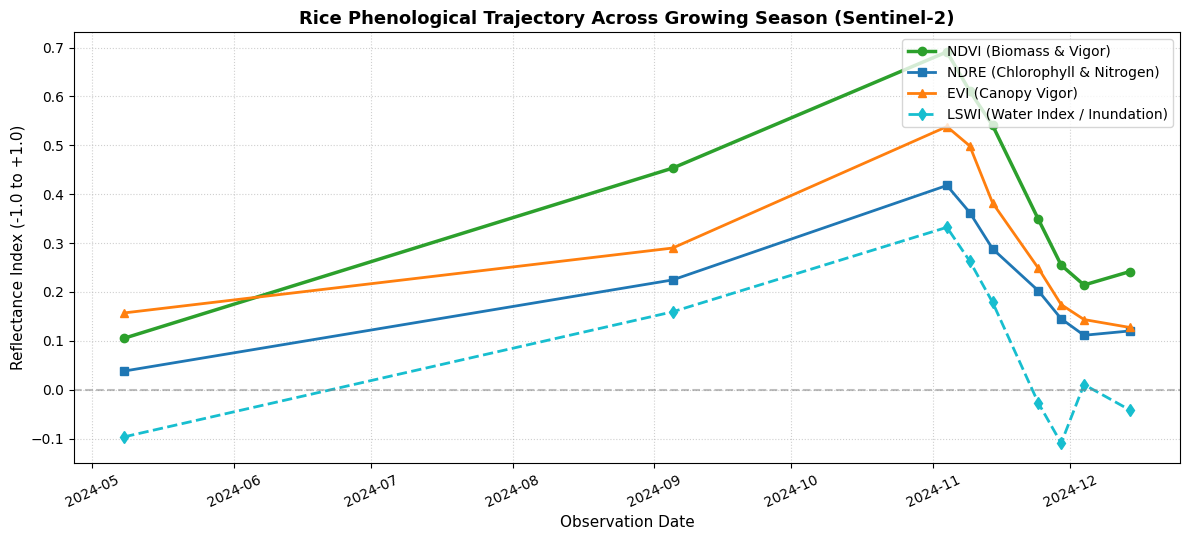

In [12]:
farm_avg = df_ts.groupby('date')[['NDVI', 'NDRE', 'EVI', 'LSWI', 'MNDWI']].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(farm_avg['date'], farm_avg['NDVI'], marker='o', linewidth=2.5, color='#2ca02c', label='NDVI (Biomass & Vigor)')
ax.plot(farm_avg['date'], farm_avg['NDRE'], marker='s', linewidth=2.0, color='#1f77b4', label='NDRE (Chlorophyll & Nitrogen)')
ax.plot(farm_avg['date'], farm_avg['EVI'], marker='^', linewidth=2.0, color='#ff7f0e', label='EVI (Canopy Vigor)')
ax.plot(farm_avg['date'], farm_avg['LSWI'], marker='d', linewidth=2.0, color='#17becf', linestyle='--', label='LSWI (Water Index / Inundation)')

ax.set_title("Rice Phenological Trajectory Across Growing Season (Sentinel-2)", fontsize=13, fontweight='bold')
ax.set_xlabel("Observation Date", fontsize=11)
ax.set_ylabel("Reflectance Index (-1.0 to +1.0)", fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True, fontsize=10)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## Step 12: Export tabular dataset to Apache GeoParquet format

In [13]:
os.makedirs('data', exist_ok=True)
parquet_path = 'data/rice_farm_timeseries.parquet'

geo_df = df_ts.merge(gdf_farm[['plot_id', 'geometry']], on='plot_id', how='left')
geo_gdf = gpd.GeoDataFrame(geo_df, geometry='geometry', crs='EPSG:4326')
geo_gdf.to_parquet(parquet_path, engine='pyarrow', index=False)

print("Saved GeoParquet:", parquet_path)
print(f"File size on disk: {os.path.getsize(parquet_path)/1024:.2f} KB")

Saved GeoParquet: data/rice_farm_timeseries.parquet
File size on disk: 19.69 KB


## Step 13: Extract and export true pixel-level spatial raster grid to Zarr store
We extract multi-temporal pixel grids (lat x lon) at 30m resolution for key phenological stages and store as Zarr.

In [14]:
bounds = gdf_farm.total_bounds
geom_bbox = ee.Geometry.BBox(float(bounds[0]), float(bounds[1]), float(bounds[2]), float(bounds[3]))

# Key stages: Early establishment/flooding, Peak vegetative, Ripening/Senescence
stages = [
    ('Early_Flooding', '2024-05-01', '2024-06-15'),
    ('Peak_Vegetative', '2024-10-15', '2024-11-15'),
    ('Ripening_Harvest', '2024-11-20', '2024-12-15')
]

stage_arrays = {}
bands_to_extract = ['NDVI', 'NDRE', 'LSWI']

for stage_name, s_date, e_date in stages:
    comp = (s2_collection.filterBounds(geom_bbox)
            .filterDate(s_date, e_date)
            .median()
            .select(bands_to_extract))
    # Extract 2D pixel array via geemap
    arr = geemap.ee_to_numpy(comp, region=geom_bbox, scale=30)
    stage_arrays[stage_name] = arr
    print(f"Extracted pixel grid for {stage_name}: shape {arr.shape} ({arr.shape[0]*arr.shape[1]} pixels)")

# Build Xarray Dataset with spatial coordinates
n_lat, n_lon = stage_arrays['Peak_Vegetative'].shape[:2]
lat_coords = np.linspace(bounds[3], bounds[1], n_lat)
lon_coords = np.linspace(bounds[0], bounds[2], n_lon)
time_coords = [s[0] for s in stages]

data_vars = {}
for i, band_name in enumerate(bands_to_extract):
    stacked = np.stack([stage_arrays[s[0]][:, :, i] for s in stages], axis=0) # (time, lat, lon)
    data_vars[band_name] = (['time', 'lat', 'lon'], stacked)

pixel_ds = xr.Dataset(
    data_vars=data_vars,
    coords={'time': time_coords, 'lat': lat_coords, 'lon': lon_coords},
    attrs={
        'title': 'Rice Farm Pixel-Level Sentinel-2 Raster Cube',
        'spatial_resolution': '30m',
        'crop': 'Paddy Rice (Oryza sativa)',
        'bands': ', '.join(bands_to_extract)
    }
)

zarr_pixel_path = 'data/rice_farm_pixel_cube.zarr'
pixel_ds.to_zarr(zarr_pixel_path, mode='w')
print("Saved Pixel-Level Zarr Cube to:", zarr_pixel_path)
display(pixel_ds)

Extracted pixel grid for Early_Flooding: shape (95, 117, 3) (11115 pixels)
Extracted pixel grid for Peak_Vegetative: shape (95, 117, 3) (11115 pixels)
Extracted pixel grid for Ripening_Harvest: shape (95, 117, 3) (11115 pixels)
Saved Pixel-Level Zarr Cube to: data/rice_farm_pixel_cube.zarr


<xarray.Dataset> Size: 402kB
Dimensions:  (time: 3, lat: 95, lon: 117)
Coordinates:
  * time     (time) <U16 192B 'Early_Flooding' ... 'Ripening_Harvest'
  * lat      (lat) float64 760B 7.905 7.904 7.904 7.904 ... 7.88 7.88 7.88 7.879
  * lon      (lon) float64 936B 8.314 8.314 8.315 8.315 ... 8.345 8.345 8.345
Data variables:
    NDVI     (time, lat, lon) float32 133kB 0.1443 0.1233 0.1357 ... 0.691 0.753
    NDRE     (time, lat, lon) float32 133kB 0.08122 0.06984 ... 0.4621 0.4938
    LSWI     (time, lat, lon) float32 133kB -0.0406 -0.05556 ... 0.2403 0.2832
Attributes:
    title:               Rice Farm Pixel-Level Sentinel-2 Raster Cube
    spatial_resolution:  30m
    crop:                Paddy Rice (Oryza sativa)
    bands:               NDVI, NDRE, LSWI